# Chapter 7: Support Vector Machines and Kernel Methods

*Summary notebook untuk **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025) — Chapter 7.*

Bab ini membahas **Support Vector Machines (SVM)**, metode supervised learning untuk klasifikasi maupun regresi. Fokus utamanya adalah mencari batas keputusan yang memisahkan kelas dengan margin yang besar, menggunakan kernel untuk pola nonlinier, memilih parameter model, menangani data berdimensi tinggi, dan mengevaluasi hasil klasifikasi.

Topik utama bab:

1. Introduction to SVMs
2. Kernel functions and their applications
3. Tuning SVM parameters
4. SVMs in high-dimensional spaces
5. Evaluating SVM models

Contoh menggunakan dataset yang tersedia di scikit-learn atau dataset sintetis agar notebook dapat dijalankan tanpa mengunduh data eksternal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import sklearn
print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version: {np.__version__}")

scikit-learn version: 1.8.0
NumPy version: 2.3.5


> **Catatan versi.** Buku mengacu pada scikit-learn 1.5+. Beberapa parameter dapat berubah pada versi berikutnya. Notebook ini menggunakan API SVM yang umum tersedia pada versi modern. Hasil angka dapat sedikit berbeda bergantung pada versi pustaka.

## 1. Introduction to SVMs

### Ringkasan

**Support Vector Machine (SVM)** mencari *hyperplane* atau batas keputusan yang memisahkan kelas. SVM berusaha memaksimalkan **margin**, yaitu jarak antara batas keputusan dan titik data terdekat dari setiap kelas.

Titik data yang paling dekat dengan batas tersebut disebut **support vectors**. Titik-titik ini berpengaruh besar terhadap posisi batas keputusan.

SVM dapat digunakan untuk:

- **Klasifikasi**, melalui `SVC` atau `LinearSVC`.
- **Regresi**, melalui `SVR`.

SVM sensitif terhadap skala fitur. Karena itu, standardisasi umumnya ditempatkan dalam `Pipeline` agar transformasi dipelajari hanya dari data latih.

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=2024, stratify=y
)

svm_linear = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0)
)
svm_linear.fit(X_train, y_train)
y_pred = svm_linear.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.978
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



**Membaca hasil.** `accuracy` menunjukkan proporsi prediksi yang benar. Laporan klasifikasi juga menampilkan precision, recall, dan F1-score untuk setiap kelas. Nilai yang tinggi menunjukkan performa yang baik pada pembagian data uji ini, tetapi tidak menjamin hasil yang sama pada semua dataset.

In [3]:
# Jumlah support vectors pada setiap kelas
svc_model = svm_linear.named_steps["svc"]
print("Jumlah support vectors per kelas:", svc_model.n_support_)
print("Total support vectors:", svc_model.n_support_.sum())

Jumlah support vectors per kelas: [ 2 10  9]
Total support vectors: 21


### SVM untuk regresi

`SVR` memprediksi nilai numerik. Berbeda dari regresi biasa, SVR menggunakan konsep *epsilon-insensitive tube*: kesalahan yang masih berada dalam rentang epsilon tidak dikenai penalti dalam fungsi kerugian. Contoh berikut memakai data regresi sintetis.

In [4]:
from sklearn.datasets import make_regression
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_reg, y_reg = make_regression(
    n_samples=300, n_features=4, noise=18, random_state=2024
)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=2024
)

svr_model = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1))
svr_model.fit(Xr_train, yr_train)
yr_pred = svr_model.predict(Xr_test)

print(f"MAE : {mean_absolute_error(yr_test, yr_pred):.2f}")
print(f"MSE : {mean_squared_error(yr_test, yr_pred):.2f}")
print(f"R²  : {r2_score(yr_test, yr_pred):.3f}")

MAE : 43.60
MSE : 5481.02
R²  : 0.620


**Catatan metrik regresi:** MAE dan MSE mengukur besar kesalahan (semakin kecil biasanya semakin baik), sedangkan R² mengukur seberapa jauh model menjelaskan variasi target (nilai mendekati 1 umumnya lebih baik). Nilai yang layak tetap bergantung pada konteks masalah.

## 2. Kernel Functions and Their Applications

### Ringkasan

Kernel memungkinkan SVM memodelkan hubungan nonlinier tanpa harus menghitung transformasi fitur berdimensi tinggi secara eksplisit. Pilihan kernel yang umum:

| Kernel | Kegunaan umum |
|:--|:--|
| `linear` | Batas keputusan linear; sering menjadi baseline yang baik |
| `poly` | Memodelkan interaksi polinomial antarfitur |
| `rbf` | Menangani pola nonlinier yang lebih fleksibel |
| `sigmoid` | Bentuk fungsi yang menyerupai aktivasi sigmoid; penggunaannya lebih khusus |

Tidak ada kernel yang selalu terbaik. Pilihan perlu diuji pada data dan metrik yang sesuai.

In [5]:
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score

X_moon, y_moon = make_moons(n_samples=500, noise=0.25, random_state=2024)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_moon, y_moon, test_size=0.30, random_state=2024, stratify=y_moon
)

kernel_results = []
models = {}
for kernel in ["linear", "poly", "rbf"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1.0, degree=3))
    model.fit(Xm_train, ym_train)
    pred = model.predict(Xm_test)
    kernel_results.append({"Kernel": kernel, "Accuracy": accuracy_score(ym_test, pred)})
    models[kernel] = model

pd.DataFrame(kernel_results).sort_values("Accuracy", ascending=False)

,Kernel,Accuracy
2,rbf,0.933333
1,poly,0.866667
0,linear,0.826667


**Membaca hasil.** Dataset `make_moons` memiliki pola melengkung sehingga kernel nonlinier seperti RBF dapat menangkap bentuk batas kelas yang tidak mudah dipisahkan oleh garis lurus. Skor tetap dipengaruhi oleh tingkat noise dan pembagian data.

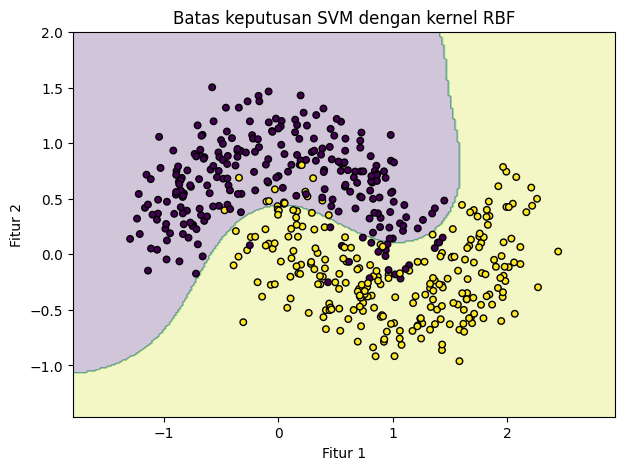

In [6]:
# Visualisasi batas keputusan untuk kernel RBF
model_rbf = models["rbf"]
x_min, x_max = X_moon[:, 0].min() - 0.5, X_moon[:, 0].max() + 0.5
y_min, y_max = X_moon[:, 1].min() - 0.5, X_moon[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = model_rbf.predict(grid).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.25)
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, edgecolors="black", s=22)
plt.title("Batas keputusan SVM dengan kernel RBF")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

### Parameter kernel yang penting

- **`C`** mengatur kompromi antara margin yang lebar dan kesalahan klasifikasi pada data latih. `C` besar berusaha lebih keras mengklasifikasikan data latih dengan benar, tetapi dapat meningkatkan risiko overfitting.
- **`gamma`** pada kernel RBF menentukan jangkauan pengaruh setiap titik. Nilai besar menghasilkan batas yang lebih lokal dan kompleks; nilai kecil menghasilkan batas yang lebih halus.
- **`degree`** mengatur derajat polinomial ketika `kernel="poly"`.

Parameter-parameter ini biasanya diuji melalui validasi silang, bukan dipilih hanya berdasarkan performa data latih.

## 3. Tuning SVM Parameters

### Ringkasan

**Hyperparameter tuning** mencari kombinasi parameter yang memberi performa validasi terbaik. `GridSearchCV` mencoba kombinasi yang ditentukan dan mengevaluasinya melalui cross-validation.

Untuk SVM dengan kernel RBF, kombinasi `C` dan `gamma` merupakan titik awal yang umum. Standardisasi dimasukkan ke dalam `Pipeline` sehingga pada setiap fold, scaler hanya mempelajari statistik dari bagian data latih fold tersebut.

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

svm_pipeline = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
search = GridSearchCV(
    svm_pipeline, param_grid, cv=cv, scoring="accuracy", n_jobs=-1
)
search.fit(Xm_train, ym_train)

print("Parameter terbaik:", search.best_params_)
print(f"Rata-rata accuracy CV terbaik: {search.best_score_:.3f}")
print(f"Accuracy pada test set: {search.score(Xm_test, ym_test):.3f}")

Parameter terbaik: {'svc__C': 1, 'svc__gamma': 1}
Rata-rata accuracy CV terbaik: 0.929
Accuracy pada test set: 0.960


**Membaca hasil.** `best_score_` merupakan skor rata-rata cross-validation pada data pelatihan, sedangkan skor test dihitung pada data uji yang ditahan terpisah. Jangan memilih parameter berdasarkan data uji, karena hal itu membuat evaluasi akhir menjadi bias.

In [8]:
# Ringkasan beberapa kombinasi terbaik
cv_results = pd.DataFrame(search.cv_results_)
cv_results[["param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score"]].sort_values(
    "mean_test_score", ascending=False
).head(10).reset_index(drop=True)

,param_svc__C,param_svc__gamma,mean_test_score,std_test_score
0,1.0,1,0.928571,0.015649
1,10.0,1,0.928571,0.012778
2,10.0,scale,0.925714,0.018952
3,100.0,scale,0.925714,0.010690
4,100.0,1,0.920000,0.014569
5,1.0,scale,0.914286,0.032576
6,100.0,0.1,0.914286,0.034993
7,0.1,1,0.894286,0.024908
8,0.1,scale,0.891429,0.024908
9,10.0,0.1,0.888571,0.029137


### Mengapa validasi silang diperlukan?

Satu pembagian train/test dapat memberikan hasil yang kebetulan terlalu baik atau terlalu buruk. Cross-validation mengulangi evaluasi pada beberapa fold sehingga memberikan gambaran performa yang lebih stabil. Stratified cross-validation menjaga proporsi kelas pada setiap fold untuk masalah klasifikasi.

## 4. SVMs in High-Dimensional Spaces

### Ringkasan

SVM sering berguna ketika jumlah fitur relatif besar, termasuk pada data teks atau data biologis. Namun, banyak fitur tidak otomatis membuat model menjadi lebih baik. Fitur yang tidak relevan, skala yang berbeda, dan jumlah sampel yang terbatas tetap dapat memengaruhi hasil.

`LinearSVC` menyediakan pendekatan SVM linear yang sering efisien untuk ruang fitur besar. Untuk data berdimensi tinggi, model linear dapat menjadi baseline yang lebih hemat komputasi dibanding kernel nonlinier.

In [9]:
from sklearn.datasets import make_classification
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score

X_high, y_high = make_classification(
    n_samples=700, n_features=100, n_informative=15, n_redundant=10,
    n_repeated=0, n_classes=2, class_sep=1.0, random_state=2024
)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_high, y_high, test_size=0.25, random_state=2024, stratify=y_high
)

linear_high = make_pipeline(StandardScaler(), LinearSVC(C=1.0, max_iter=10000, random_state=2024))
linear_high.fit(Xh_train, yh_train)
yh_pred = linear_high.predict(Xh_test)
print(f"Accuracy: {accuracy_score(yh_test, yh_pred):.3f}")
print(f"F1-score: {f1_score(yh_test, yh_pred):.3f}")

Accuracy: 0.680
F1-score: 0.674


**Interpretasi.** Contoh ini membuat 100 fitur, tetapi hanya sebagian yang informatif. Model dievaluasi pada data yang tidak dipakai untuk pelatihan. Dalam praktik, periksa juga kestabilan skor, biaya komputasi, dan apakah fitur benar-benar tersedia saat model digunakan.

In [10]:
# Periksa jumlah fitur dan koefisien model linear
linear_estimator = linear_high.named_steps["linearsvc"]
print("Jumlah fitur:", X_high.shape[1])
print("Bentuk matriks koefisien:", linear_estimator.coef_.shape)
print("Lima koefisien pertama:", np.round(linear_estimator.coef_[0, :5], 3))

Jumlah fitur: 100
Bentuk matriks koefisien: (1, 100)
Lima koefisien pertama: [ 0.053 -0.016  0.019 -0.023 -0.028]


### Praktik untuk data berdimensi tinggi

- Terapkan scaling pada fitur numerik bila sesuai dengan karakteristik data.
- Gunakan `Pipeline` agar preprocessing dan model dievaluasi bersama tanpa data leakage.
- Mulai dari model linear sebelum mencoba kernel yang lebih kompleks.
- Tuning `C` dengan validasi silang.
- Untuk data yang sangat besar, pertimbangkan biaya pelatihan dan memori dari setiap pendekatan.

## 5. Evaluating SVM Models

### Ringkasan

Evaluasi tidak cukup hanya melihat accuracy. Untuk klasifikasi biner, metrik yang dapat digunakan antara lain:

- **Precision**: proporsi prediksi positif yang benar-benar positif.
- **Recall**: proporsi kasus positif aktual yang berhasil ditemukan.
- **F1-score**: rata-rata harmonik precision dan recall.
- **ROC curve dan AUC**: menilai kemampuan model membedakan kelas pada berbagai threshold.

Pemilihan metrik bergantung pada biaya kesalahan. Contohnya, pada skrining penyakit, false negative mungkin perlu diperhatikan secara khusus.

In [11]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

cancer = load_breast_cancer()
Xc, yc = cancer.data, cancer.target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.30, random_state=2024, stratify=yc
)

svm_eval = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", probability=True, random_state=2024)
)
svm_eval.fit(Xc_train, yc_train)
yc_pred = svm_eval.predict(Xc_test)
yc_prob = svm_eval.predict_proba(Xc_test)[:, 1]

print(classification_report(yc_test, yc_pred, target_names=cancer.target_names))
print(f"ROC AUC: {roc_auc_score(yc_test, yc_prob):.3f}")

              precision    recall  f1-score   support

   malignant       0.95      0.94      0.94        64
      benign       0.96      0.97      0.97       107

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171

ROC AUC: 0.995


**Membaca hasil.** Dataset ini memiliki dua kelas, dengan label yang dijelaskan oleh `cancer.target_names`. Pastikan mengetahui kelas mana yang dianggap positif sebelum menafsirkan precision, recall, atau probabilitas. Untuk `SVC`, probabilitas perlu diaktifkan dengan `probability=True`, yang menambah biaya pelatihan.

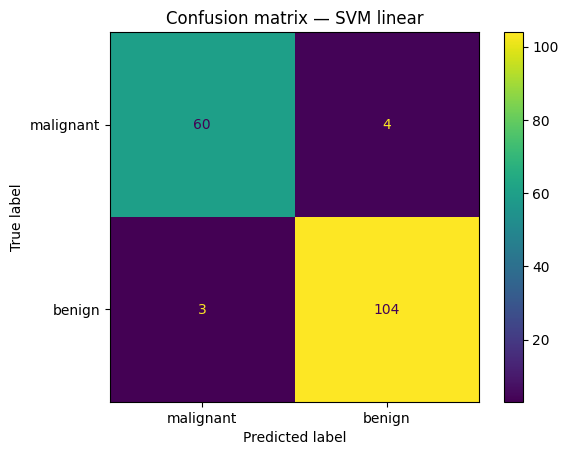

In [12]:
cm = confusion_matrix(yc_test, yc_pred)
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
display_cm.plot()
plt.title("Confusion matrix — SVM linear")
plt.show()

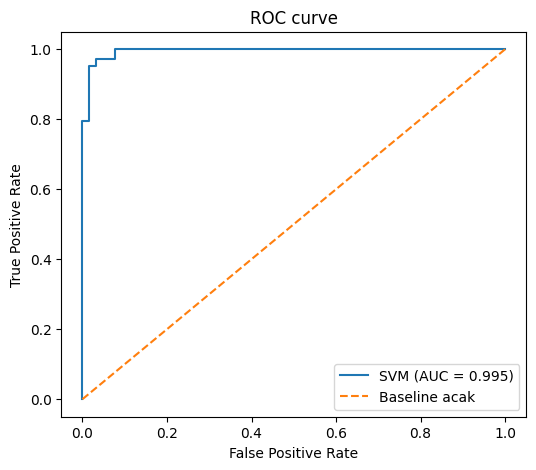

In [13]:
fpr, tpr, thresholds = roc_curve(yc_test, yc_prob)
auc_value = roc_auc_score(yc_test, yc_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"SVM (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Baseline acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.show()

### Hal yang perlu diperhatikan ketika mengevaluasi SVM

1. Pisahkan data latih dan data uji sebelum melakukan preprocessing yang mempelajari parameter.
2. Gunakan cross-validation untuk memilih hyperparameter.
3. Pilih metrik yang sesuai dengan tujuan dan konsekuensi kesalahan.
4. Jangan menganggap skor dari satu dataset berlaku untuk semua kondisi nyata.
5. Jika kelas tidak seimbang, pertimbangkan precision, recall, F1-score, ROC AUC, atau metrik lain yang sesuai, bukan accuracy saja.

## Kesimpulan

Bab ini memperkenalkan SVM sebagai metode untuk klasifikasi dan regresi. Konsep pentingnya adalah **margin**, **support vectors**, dan **kernel**. Kernel linear cocok sebagai baseline sederhana, sedangkan kernel seperti RBF dapat mempelajari batas keputusan nonlinier. Performa SVM dipengaruhi oleh parameter seperti `C` dan `gamma`, sehingga tuning dengan cross-validation sangat berguna.

Sebelum menggunakan model, pastikan preprocessing dilakukan tanpa data leakage, pilih metrik evaluasi yang sesuai, dan bandingkan hasil pada data uji yang terpisah. Model dengan skor tertinggi bukan selalu pilihan terbaik apabila biaya komputasi, interpretabilitas, atau kebutuhan penggunaan nyata juga penting.

### Latihan mandiri

1. Ganti `kernel="linear"` menjadi `kernel="rbf"` pada dataset Iris. Apakah hasilnya berubah?
2. Pada dataset `make_moons`, coba `C` bernilai `0.1`, `1`, dan `100`. Amati perubahan batas keputusan.
3. Ubah rentang `gamma` pada `GridSearchCV`. Apakah parameter terbaik berubah?
4. Jelaskan mengapa scaling dimasukkan ke dalam `Pipeline` saat menggunakan cross-validation.
5. Pada dataset breast cancer, bandingkan accuracy dengan recall untuk kelas yang menjadi fokus analisis. Metrik mana yang lebih penting untuk kasus yang sedang dibahas?